# M Dim Ablation

This notebook compares M embedding dimensions using averaged multi-seed PCA query projection runs.

## Setup

The notebook reads the grouped experiment result from `output/summary.json`.

In [1]:
from __future__ import annotations

import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

OUTPUT_DIR = Path("output")
SUMMARY_PATH = OUTPUT_DIR / "summary.json"

plt.rcParams.update(
    {
        "figure.dpi": 150,
        "savefig.dpi": 300,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "axes.edgecolor": "#D1D5DB",
        "axes.labelcolor": "#111827",
        "axes.titlesize": 14,
        "axes.titleweight": "bold",
        "axes.labelsize": 11,
        "xtick.color": "#374151",
        "ytick.color": "#374151",
        "grid.color": "#E5E7EB",
        "grid.linewidth": 0.8,
        "legend.frameon": False,
        "font.size": 10,
    }
)

SPLIT_COLORS = {
    "dev": "#2563EB",
    "test": "#059669",
    "xeval": "#D97706",
}


## Load Results

The aggregate table contains one averaged row per M dimension.

In [2]:
with SUMMARY_PATH.open("r", encoding="utf-8") as file:
    summary = json.load(file)

runs = summary["runs"]
aggregates = summary["aggregate"]


def flatten_aggregate(item: dict) -> dict:
    row = {
        "m_dim": item["m_dim"],
        "num_seeds": item["num_seeds"],
        "best_epoch": item["best_epoch"],
    }

    for split_name in ("best_dev", "test", "xeval"):
        for metric_name in ("loss", "top1", "ndcg"):
            row[f"{split_name}_{metric_name}"] = item[split_name][metric_name]

    return row


aggregate_df = pd.DataFrame([flatten_aggregate(item) for item in aggregates])
aggregate_df = aggregate_df.sort_values("m_dim").reset_index(drop=True)

display(aggregate_df)


,m_dim,num_seeds,best_epoch,best_dev_loss,best_dev_top1,best_dev_ndcg,test_loss,test_top1,test_ndcg,xeval_loss,xeval_top1,xeval_ndcg
0,0,5,1.8,1.610649,0.035714,0.692463,1.610878,0.178571,0.728734,1.608733,0.248291,0.755067
1,8,5,18.0,1.577951,0.492857,0.849840,1.585774,0.342857,0.817424,1.589101,0.314103,0.793912
2,16,5,18.6,1.567848,0.500000,0.854947,1.578763,0.335714,0.814424,1.579953,0.314103,0.805494
3,32,5,16.2,1.563525,0.528571,0.864773,1.576720,0.378571,0.823018,1.574378,0.319231,0.812487
4,64,5,11.0,1.566560,0.571429,0.873386,1.580027,0.357143,0.822471,1.575707,0.339744,0.819374
5,128,5,11.4,1.561138,0.535714,0.867587,1.576781,0.371429,0.817378,1.571297,0.316667,0.816522
6,256,5,6.8,1.565841,0.521429,0.867612,1.579813,0.350000,0.815395,1.574188,0.325641,0.819408


## Per-Seed Results

This table keeps the raw seed-level results available for inspection.

In [3]:
def best_epoch_from_history(run: dict) -> int:
    history = run["history"]
    best_item = max(history, key=lambda item: item["dev"]["ndcg"])
    return int(best_item["epoch"])


seed_records = []
for run in runs:
    experiment = run["experiment"]
    best_dev = run["best_dev"]
    test = run["test"]
    xeval = run["xeval"]

    seed_records.append(
        {
            "run": experiment["name"],
            "m_dim": experiment["m_embedding_dim"],
            "seed": experiment["seed"],
            "best_epoch": best_epoch_from_history(run),
            "best_dev_top1": best_dev["top1"],
            "best_dev_ndcg": best_dev["ndcg"],
            "test_top1": test["top1"],
            "test_ndcg": test["ndcg"],
            "xeval_top1": xeval["top1"],
            "xeval_ndcg": xeval["ndcg"],
        }
    )

seed_df = pd.DataFrame(seed_records).sort_values(["m_dim", "seed"]).reset_index(drop=True)
display(seed_df)


,run,m_dim,seed,best_epoch,best_dev_top1,best_dev_ndcg,test_top1,test_ndcg,xeval_top1,xeval_ndcg
0,m0,0,7,1,0.035714,0.691830,0.178571,0.728669,0.252137,0.756021
1,m0,0,13,1,0.035714,0.693559,0.178571,0.728018,0.252137,0.756458
2,m0,0,21,1,0.035714,0.692370,0.178571,0.728669,0.245726,0.753682
3,m0,0,42,5,0.035714,0.693305,0.178571,0.729645,0.239316,0.752917
4,m0,0,100,1,0.035714,0.691252,0.178571,0.728669,0.252137,0.756258
5,m8,8,7,19,0.428571,0.840500,0.285714,0.812518,0.326923,0.796817
6,m8,8,13,16,0.500000,0.856140,0.357143,0.813801,0.294872,0.797332
7,m8,8,21,20,0.500000,0.841563,0.392857,0.829486,0.314103,0.784129
8,m8,8,42,16,0.571429,0.862937,0.357143,0.816730,0.301282,0.792962
9,m8,8,100,19,0.464286,0.848058,0.321429,0.814584,0.333333,0.798317


## Metrics

Top-1 and nDCG values are shown as percentages.

In [4]:
metric_rows = []
for _, row in aggregate_df.iterrows():
    metric_rows.append(
        {
            "m_dim": int(row["m_dim"]),
            "seeds": int(row["num_seeds"]),
            "best_epoch": f"{row['best_epoch']:.1f}",
            "dev_top1": 100.0 * row["best_dev_top1"],
            "dev_ndcg": 100.0 * row["best_dev_ndcg"],
            "test_top1": 100.0 * row["test_top1"],
            "test_ndcg": 100.0 * row["test_ndcg"],
            "xeval_top1": 100.0 * row["xeval_top1"],
            "xeval_ndcg": 100.0 * row["xeval_ndcg"],
        }
    )

metrics_df = pd.DataFrame(metric_rows)
display(
    metrics_df.style.format(
        {
            "dev_top1": "{:.2f}",
            "dev_ndcg": "{:.2f}",
            "test_top1": "{:.2f}",
            "test_ndcg": "{:.2f}",
            "xeval_top1": "{:.2f}",
            "xeval_ndcg": "{:.2f}",
        }
    )
    .background_gradient(subset=["dev_ndcg", "test_ndcg", "xeval_ndcg"], cmap="Blues")
    .background_gradient(subset=["dev_top1", "test_top1", "xeval_top1"], cmap="Greens")
)


,m_dim,seeds,best_epoch,dev_top1,dev_ndcg,test_top1,test_ndcg,xeval_top1,xeval_ndcg
0,0,5,1.8,3.57,69.25,17.86,72.87,24.83,75.51
1,8,5,18.0,49.29,84.98,34.29,81.74,31.41,79.39
2,16,5,18.6,50.00,85.49,33.57,81.44,31.41,80.55
3,32,5,16.2,52.86,86.48,37.86,82.30,31.92,81.25
4,64,5,11.0,57.14,87.34,35.71,82.25,33.97,81.94
5,128,5,11.4,53.57,86.76,37.14,81.74,31.67,81.65
6,256,5,6.8,52.14,86.76,35.00,81.54,32.56,81.94


## Best Setting

The selected setting is the highest averaged dev nDCG, with averaged dev Top-1 as the secondary signal.

In [5]:
best = aggregate_df.sort_values(
    ["best_dev_ndcg", "best_dev_top1", "m_dim"],
    ascending=[False, False, True],
).iloc[0]

print(f"best M dim: {int(best.m_dim)}")
print(f"seeds: {int(best.num_seeds)}")
print(f"best epoch: {best.best_epoch:.1f}")
print(f"dev top1: {best.best_dev_top1:.4f}")
print(f"dev ndcg: {best.best_dev_ndcg:.4f}")
print(f"test top1: {best.test_top1:.4f}")
print(f"test ndcg: {best.test_ndcg:.4f}")
print(f"xeval top1: {best.xeval_top1:.4f}")
print(f"xeval ndcg: {best.xeval_ndcg:.4f}")


best M dim: 64
seeds: 5
best epoch: 11.0
dev top1: 0.5714
dev ndcg: 0.8734
test top1: 0.3571
test ndcg: 0.8225
xeval top1: 0.3397
xeval ndcg: 0.8194


## Delta

Each M dimension is compared against the no-M baseline `m0`.

In [6]:
baseline = aggregate_df[aggregate_df["m_dim"] == 0].iloc[0]

delta = aggregate_df[["m_dim"]].copy()
for col in [
    "best_dev_top1",
    "best_dev_ndcg",
    "test_top1",
    "test_ndcg",
    "xeval_top1",
    "xeval_ndcg",
]:
    delta[col + "_delta"] = 100.0 * (aggregate_df[col] - baseline[col])

display(
    delta.style.format({col: "{:+.2f}" for col in delta.columns if col != "m_dim"})
    .background_gradient(
        subset=[col for col in delta.columns if col != "m_dim"],
        cmap="RdYlGn",
        axis=0,
    )
)


,m_dim,best_dev_top1_delta,best_dev_ndcg_delta,test_top1_delta,test_ndcg_delta,xeval_top1_delta,xeval_ndcg_delta
0,0,+0.00,+0.00,+0.00,+0.00,+0.00,+0.00
1,8,+45.71,+15.74,+16.43,+8.87,+6.58,+3.88
2,16,+46.43,+16.25,+15.71,+8.57,+6.58,+5.04
3,32,+49.29,+17.23,+20.00,+9.43,+7.09,+5.74
4,64,+53.57,+18.09,+17.86,+9.37,+9.15,+6.43
5,128,+50.00,+17.51,+19.29,+8.86,+6.84,+6.15
6,256,+48.57,+17.51,+17.14,+8.67,+7.74,+6.43


## Split Plots

Bar charts show averaged performance for each M dimension.

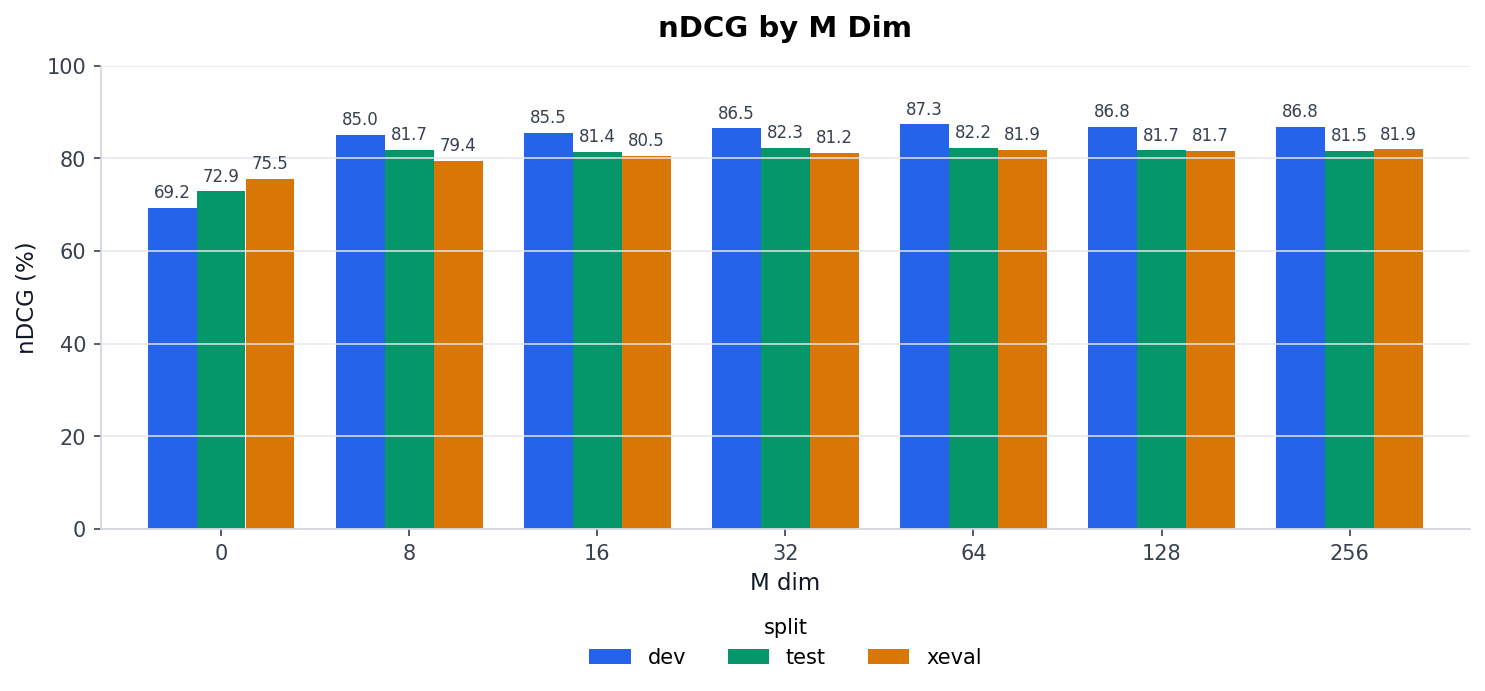

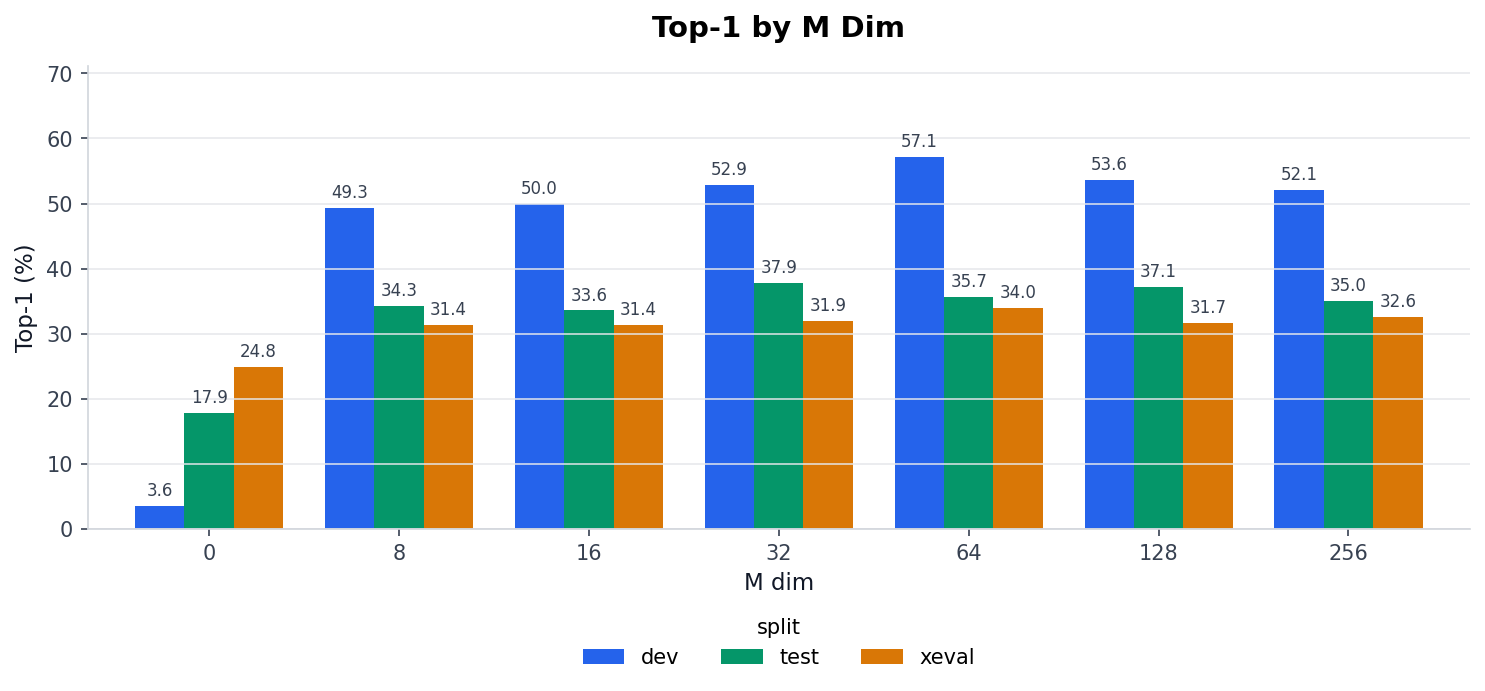

In [7]:
def finish_axis(ax, ylabel: str) -> None:
    ax.set_xlabel("M dim")
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.9)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#D1D5DB")
    ax.spines["bottom"].set_color("#D1D5DB")
    ax.legend(title="split", loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3)


def plot_metric(metric_name: str, title: str, ylabel: str) -> None:
    plot_df = aggregate_df[["m_dim", f"best_dev_{metric_name}", f"test_{metric_name}", f"xeval_{metric_name}"]].copy()
    plot_df = plot_df.rename(
        columns={
            f"best_dev_{metric_name}": "dev",
            f"test_{metric_name}": "test",
            f"xeval_{metric_name}": "xeval",
        }
    )
    plot_df[["dev", "test", "xeval"]] = plot_df[["dev", "test", "xeval"]] * 100.0

    ax = plot_df.set_index("m_dim")[["dev", "test", "xeval"]].plot(
        kind="bar",
        figsize=(10, 4.8),
        rot=0,
        width=0.78,
        color=[SPLIT_COLORS["dev"], SPLIT_COLORS["test"], SPLIT_COLORS["xeval"]],
    )

    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f", padding=3, fontsize=8, color="#374151")

    ax.set_title(title, pad=14)
    upper = float(plot_df[["dev", "test", "xeval"]].to_numpy().max())
    ax.set_ylim(0, min(100, upper + 14))
    finish_axis(ax, ylabel)
    plt.tight_layout()
    plt.show()


plot_metric("ndcg", "nDCG by M Dim", "nDCG (%)")
plot_metric("top1", "Top-1 by M Dim", "Top-1 (%)")
